## Plotting alpha mass fraction for arbitrary proton fraction

This code generalises the code from Fig_4 so that an arbitrary value of Y_p can be chosen. 

In [1]:
# Imports

import numpy as np
import matplotlib.pyplot as plt
from scipy.optimize import brentq


In [2]:
# Define constants

T = 4.0 # Temp [MeV]
m_p = 938.272 # mass of proton [MeV/c^2]
lamda = 197.326 * (2 * np.pi/(m_p * T))**(1/2) # nucleon thermal wavelength [fm^-1] assuming m_p=m_n
lamda_alpha = lamda / 2 # alpha particle thermal wavelength [fm^-1]
E_alpha = 28.3 # alpha particle binding energy [MeV]
Y_p = 0.5 # proton fraction

# virial coefficients for T = 4 MeV
b_n = 0.307
b_pn = 3.19
b_nuc = 3.50
b_alpha_n = 2.73
b_alpha = 7.44

### Calculation Process

Since z_n is no longer equal to z_p, an equation for z_p in terms of z_n must be solved before determining z_alpha. For the ideal gas and with the nucleon-nucleon interactions these are quadratic equations, and then the equation becomes a cubic and then a quartic as the rest of the interactions are included. scipy.optimize.brentq() is used to solve the cubic and quartic, finding roots over the interval specified.

In [3]:

# Calculate fugacities

z_n = np.linspace(1e-8, 0.05, 100) # range of neutron fugacities starting at small positive value

#------------------------------
# free n, p, alpha gas
#------------------------------

# ideal quadratic coefficients

a_1 = ((16*Y_p - 8)/(1 - Y_p)) * z_n**2 * np.exp(E_alpha/T)
b_1 = -1.0
c_1 = Y_p * z_n/(1 - Y_p)


z_p_1 = (2 * c_1) / (-b_1 + np.sqrt(b_1**2 - 4*a_1*c_1)) # proton fugacity calculated as roots of quadratic equation


z_alpha_1 = z_n**2 * z_p_1**2 * np.exp(E_alpha/T) # alpha particle fugacity

#------------------------------
# with b_n, b_pn, b_nuc
#------------------------------

# b_n, b_pn, b_nuc quadratic coefficients

a_2 = ((16*Y_p - 8)/(1 - Y_p)) * z_n**2 * np.exp(E_alpha/T) - 2 * b_n
b_2 = (2 * Y_p)/(1 - Y_p) * z_n * b_pn - 2 * z_n * b_pn - 1
c_2 = (Y_p/(1 - Y_p)) * (z_n + 2 * z_n**2 * b_n)

z_p_2 = (2 * c_2) / (-b_2 + np.sqrt(b_2**2 - 4*a_2*c_2)) # proton fugacity calculated as roots of quadratic equation

z_alpha_2 = z_n**2 * z_p_2**2 * np.exp(E_alpha/T) # alpha particle fugacity

#-----------------------------
# with b_alpha_n
#-----------------------------

# solve cubic

z_p_3 = []

for zn in z_n:
    a = (32 * Y_p - 16)/(1 - Y_p) * b_alpha_n * zn**2 * np.exp(E_alpha/T) - 8 * b_alpha_n * zn**2 * np.exp(E_alpha/T)
    b = ((8 * Y_p)/(1 - Y_p)) * b_alpha_n * zn**3 * np.exp(E_alpha/T) + ((16 * Y_p - 8)/(1 - Y_p)) * (zn**2 * np.exp(E_alpha/T) + 2 * zn**3 * np.exp(E_alpha/T) * b_alpha_n) - 2 * b_n
    c = ((2 * Y_p)/(1 - Y_p)) * zn * b_pn - 1 - 2 * (zn * b_pn)
    d = (Y_p/(1 - Y_p)) * (zn + 2 * zn**2 * b_n)

    def f(z_p):
        return a * z_p**3 + b * z_p**2 + c * z_p + d # cubic function in powers of z_p

    z_p = brentq(f, 0.0, 0.05)

    z_p_3.append(z_p)
z_p_3 = np.array(z_p_3)

z_alpha_3 = z_n**2 * z_p_3**2 * np.exp(E_alpha/T) # alpha particle fugacity

#----------------------------
# with b_alpha
#----------------------------

# solve quartic

z_p_4 = []

for zn in z_n:
    a = ((32 * Y_p - 16)/(1 - Y_p)) * b_alpha * zn**4 * np.exp(2 * E_alpha/T)
    b = (32 * Y_p - 16)/(1 - Y_p) * b_alpha_n * zn**2 * np.exp(E_alpha/T) - 8 * b_alpha_n * zn**2 * np.exp(E_alpha/T)
    c = ((8 * Y_p)/(1 - Y_p)) * b_alpha_n * zn**3 * np.exp(E_alpha/T) + ((16 * Y_p - 8)/(1 - Y_p)) * (zn**2 * np.exp(E_alpha/T) + 2 * zn**3 * np.exp(E_alpha/T) * b_alpha_n) - 2 * b_n
    d = ((2 * Y_p)/(1 - Y_p)) * zn * b_pn - 1 - 2 * (zn * b_pn)
    e = (Y_p/(1 - Y_p)) * (zn + 2 * zn**2 * b_n)

    def g(z_p):
        return a * z_p**4 + b * z_p**3 + c * z_p**2 + d * z_p + e # quartic function in powers of z_p

    z_p = brentq(g, 0.0, 0.05)
    z_p_4.append(z_p)
z_p_4 = np.array(z_p_4)


z_alpha_4 = z_n**2 * z_p_4**2 * np.exp(E_alpha/T) # alpha particle fugacity

In [4]:
# Calculate number densities

#------------------------------
# free n, p, alpha gas
#------------------------------
n_n_1 = (2/lamda**3) * z_n # neutron number density
n_p_1 = (2/lamda**3) * z_p_1 # proton number density
n_alpha_1 = (1/lamda_alpha**3) * z_alpha_1 # alpha particle number density
n_b_1 = (n_n_1 + n_p_1 + 4 * n_alpha_1) # baryon number density [fm^-3]

#------------------------------
# with b_n, b_pn, b_nuc
#------------------------------
n_n_2 = (2/lamda**3) * (z_n + 2 * z_n**2 * b_n + 2 * z_n * z_p_2 * b_pn)
n_p_2 = (2/lamda**3) * (z_p_2 + 2 * z_p_2**2 * b_n + 2 * z_n * z_p_2 * b_pn)
n_alpha_2 = (1/lamda_alpha**3) * z_alpha_2
n_b_2 = (n_n_2 + n_p_2 + 4 * n_alpha_2)

#-----------------------------
# with b_alpha_n
#-----------------------------
n_n_3 = (2/lamda**3) * (z_n + 2 * z_n**2 * b_n + 2 * z_n * z_p_3 * b_pn + 8 * z_n * z_alpha_3 * b_alpha_n)
n_p_3 = (2/lamda**3) * (z_p_3 + 2 * z_p_3**2 * b_n + 2 * z_n * z_p_3 * b_pn + 8 * z_p_3 * z_alpha_3 * b_alpha_n)
n_alpha_3 = (1/lamda_alpha**3) * (z_alpha_3 + 2 * z_alpha_3 * (z_n + z_p_3) * b_alpha_n)
n_b_3 = (n_n_3 + n_p_3 + 4 * n_alpha_3)

#----------------------------
# with b_alpha
#----------------------------
n_n_4 = (2/lamda**3) * (z_n + 2 * z_n**2 * b_n + 2 * z_n * z_p_4 * b_pn + 8 * z_n * z_alpha_4 * b_alpha_n)
n_p_4 = (2/lamda**3) * (z_p_4 + 2 * z_p_4**2 * b_n + 2 * z_n * z_p_4 * b_pn + 8 * z_p_4 * z_alpha_4 * b_alpha_n)
n_alpha_4 = (1/lamda_alpha**3) * (z_alpha_4 + 2 * z_alpha_4 * (z_n + z_p_4) * b_alpha_n + 2 * z_alpha_4**2 * b_alpha)
n_b_4 = (n_n_4 + n_p_4 + 4 * n_alpha_4)

In [5]:
# Calculate alpha mass fractions


x_alpha_1 = 4 * n_alpha_1 / n_b_1 # alpha mass fraction
x_alpha_2 = 4 * n_alpha_2 / n_b_2 
x_alpha_3 = 4 * n_alpha_3 / n_b_3 
x_alpha_4 = 4 * n_alpha_4 / n_b_4 


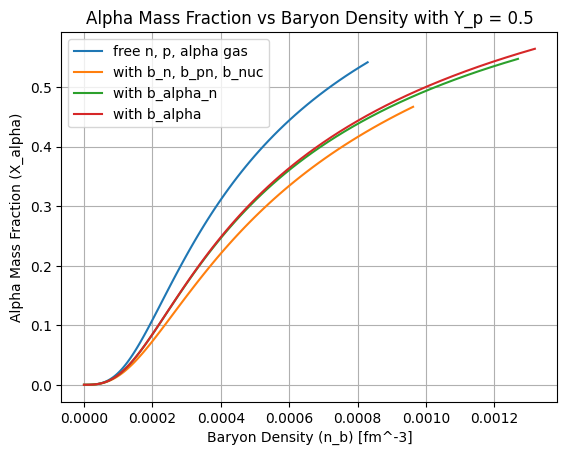

In [6]:
# Plot results

plt.plot(n_b_1, x_alpha_1, label='free n, p, alpha gas')
plt.plot(n_b_2, x_alpha_2, label='with b_n, b_pn, b_nuc')
plt.plot(n_b_3, x_alpha_3, label='with b_alpha_n')
plt.plot(n_b_4, x_alpha_4, label='with b_alpha')
plt.xlabel('Baryon Density (n_b) [fm^-3]')
plt.ylabel('Alpha Mass Fraction (X_alpha)')
plt.title(f'Alpha Mass Fraction vs Baryon Density with Y_p = {Y_p}')
plt.grid()
plt.legend()
plt.show()
